In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [19]:
def generate_histogram(image):
    # Calculate the histogram of the grayscale image
    histogram = cv2.calcHist(
        [image],      # Input image
        [0],          # Channel 0 for grayscale image
        None,         # No mask → use the entire image else use mask area: [100:300, 100:300]
        [256],        # Number of histogram bins
        [0, 256])     # Intensity range  #  [0, 256) range covering intensity values 0–255

    return histogram

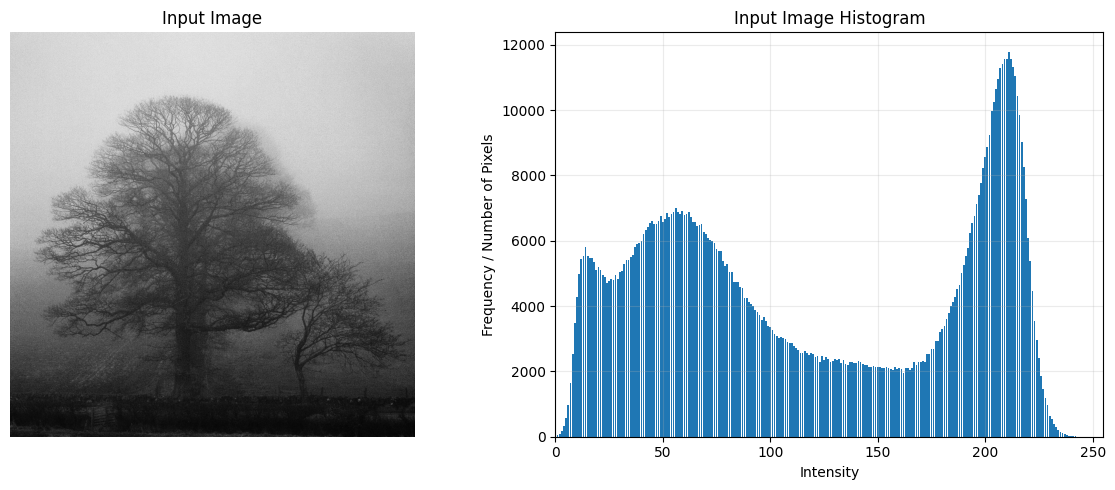

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the input image
input_path = r"D:\SEM_5\DSIP\DSIP_practical\open_ended_problem_8\tree.jpg"
input_image = cv2.imread(input_path)

# Check if image is loaded
if input_image is None:
    print("Error: Image not found. Please check the path.")
else:

    # Convert the image to grayscale
    gray_image = cv2.cvtColor(input_image, cv2.COLOR_BGR2GRAY)

    # Generate histogram of the grayscale image
    input_hist = cv2.calcHist([gray_image], [0], None, [256], [0, 256])

    # Convert histogram to 1D array
    input_hist = input_hist.flatten()

    # Create intensity values from 0 to 255
    intensity = np.arange(256)

    # Display image and histogram side by side
    plt.figure(figsize=(12, 5))

    # Display the grayscale image
    plt.subplot(1, 2, 1)
    plt.imshow(gray_image, cmap="gray")
    plt.title("Input Image")
    plt.axis("off")

    # Display the histogram
    plt.subplot(1, 2, 2)
    plt.bar(intensity, input_hist)
    plt.title("Input Image Histogram")
    plt.xlabel("Intensity")
    plt.ylabel("Frequency / Number of Pixels")
    plt.xlim([0, 255])
    plt.grid(alpha=0.25)

    # Adjust spacing
    plt.tight_layout()

    # Display the result
    plt.show()

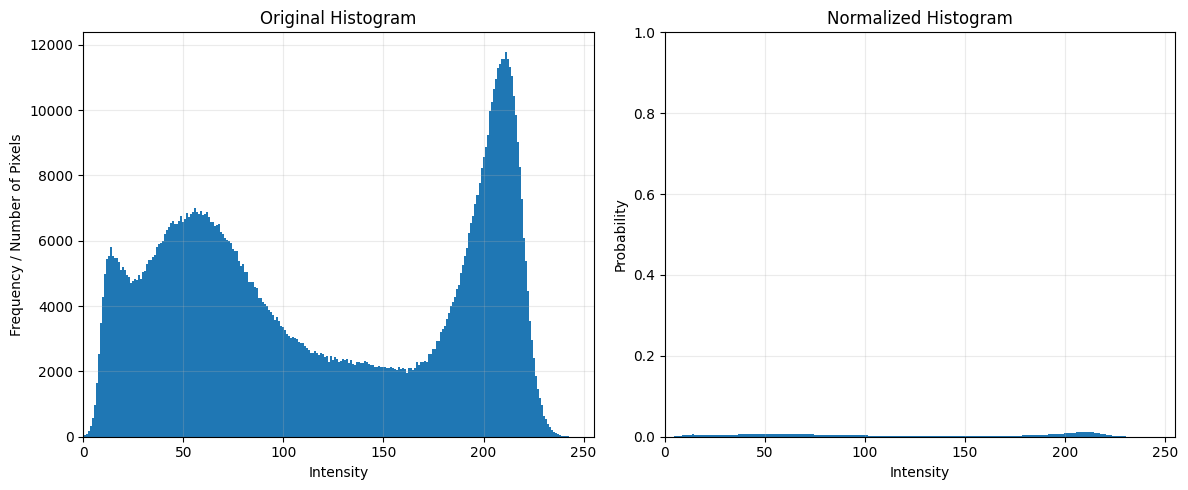

In [21]:
# Calculate the total number of pixels
total_pixels = gray_image.size

# Normalize the histogram
normalized_hist = input_hist / total_pixels

# Display original and normalized histograms
plt.figure(figsize=(12, 5))

# Original histogram
plt.subplot(1, 2, 1)
plt.bar(intensity, input_hist, width=1)
plt.title("Original Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency / Number of Pixels")
plt.xlim([0, 255])
plt.grid(alpha=0.25)

# Normalized histogram
plt.subplot(1, 2, 2)
plt.bar(intensity, normalized_hist)
plt.title("Normalized Histogram")
plt.xlabel("Intensity")
plt.ylabel("Probability")
plt.xlim([0, 255])
plt.ylim([0, 1])
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [22]:
def perform_histogram_equalization(image):
  # Convert image to grayscale
  gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

  # Apply histogram equalization
  equalized_image = cv2.equalizeHist(gray_image)
  return equalized_image

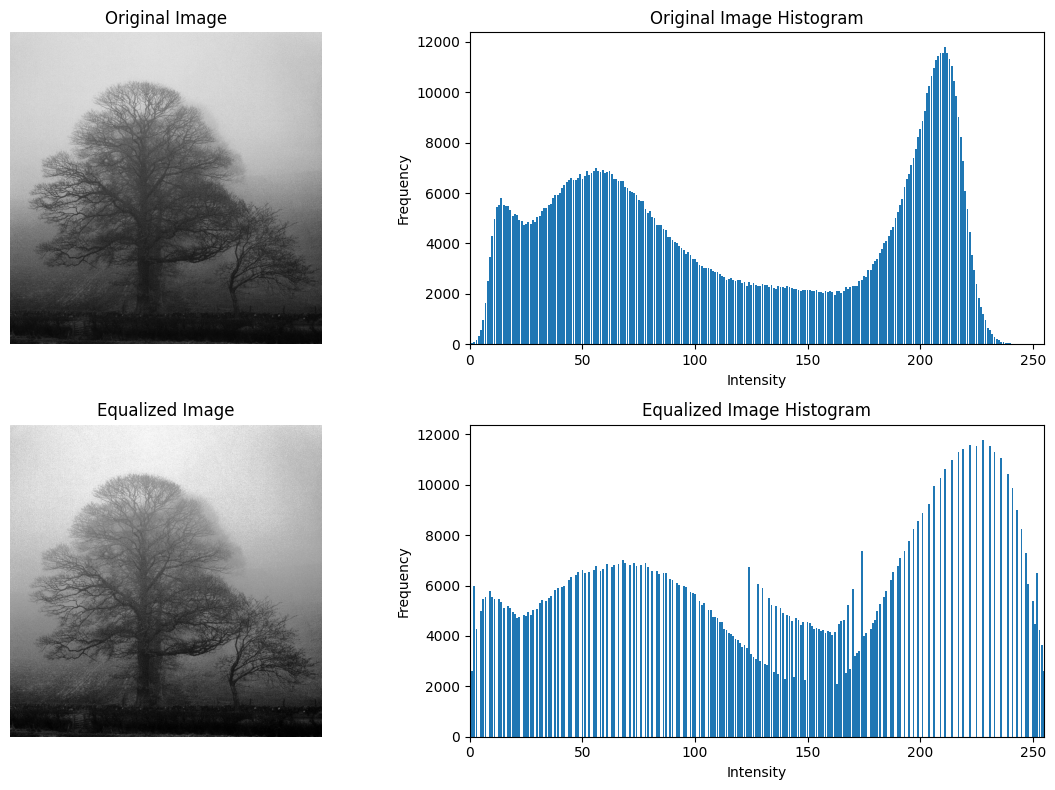

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load image
input_path = r"D:\SEM_5\DSIP\DSIP_practical\open_ended_problem_8\tree.jpg"

original_image = cv2.imread(input_path, cv2.IMREAD_GRAYSCALE)

# Check image
if original_image is None:
    print("Image not found. Check the image path.")
else:
    # 1. Histogram of Original Image
    original_hist = cv2.calcHist(
        [original_image], [0], None, [256], [0, 256]
    ).flatten()

    # 2. Histogram Equalization
    equalized_image = cv2.equalizeHist(original_image)

    # Histogram of Equalized Image
    equalized_hist = cv2.calcHist(
        [equalized_image], [0], None, [256], [0, 256]
    ).flatten()

    # Intensity values
    intensity = np.arange(256)

    # Display
    plt.figure(figsize=(12, 8))

    # 1. Original Image
    plt.subplot(2, 2, 1)
    plt.imshow(original_image, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    # 2. Original Histogram
    plt.subplot(2, 2, 2)
    plt.bar(intensity, original_hist)
    plt.title("Original Image Histogram")
    plt.xlabel("Intensity")
    plt.ylabel("Frequency")
    plt.xlim(0, 255)

    # 3. Equalized Image
    plt.subplot(2, 2, 3)
    plt.imshow(equalized_image, cmap="gray")
    plt.title("Equalized Image")
    plt.axis("off")

    # 4. Equalized Histogram
    plt.subplot(2, 2, 4)
    plt.bar(intensity, equalized_hist)
    plt.title("Equalized Image Histogram")
    plt.xlabel("Intensity")
    plt.ylabel("Frequency")
    plt.xlim(0, 255)

    # Adjust layout
    plt.tight_layout()
    plt.show()

In [24]:
import cv2

# Load the input image
input_path = r"D:\SEM_5\DSIP\DSIP_practical\open_ended_problem_8\tree.jpg"
input_image = cv2.imread(input_path)

# Convert input image to grayscale
gray_image = cv2.cvtColor(input_image, cv2.COLOR_BGR2GRAY)

# Load the reference image
reference_path = r"D:\SEM_5\DSIP\DSIP_practical\open_ended_problem_8\city.jpg"
reference_image = cv2.imread(reference_path)

# Check reference image
if reference_image is None:
    print("Reference image not found. Check the path.")
else:
    # Convert reference image to grayscale
    gray_reference = cv2.cvtColor(reference_image, cv2.COLOR_BGR2GRAY)

    print("Both images loaded successfully!")

Both images loaded successfully!


In [25]:
# Load the input image
input_path = r"D:\SEM_5\DSIP\DSIP_practical\open_ended_problem_8\tree.jpg"
input_image = cv2.imread(input_path)

# Convert the image to grayscale
gray_image = cv2.cvtColor(input_image, cv2.COLOR_BGR2GRAY)

# Load the reference image
input_path = r"D:\SEM_5\DSIP\DSIP_practical\open_ended_problem_8\city.jpg"
input_image = cv2.imread(reference_path)

# Convert the reference image to grayscale
gray_reference = cv2.cvtColor(reference_image, cv2.COLOR_BGR2GRAY)


In [26]:
from skimage.exposure import match_histograms

In [27]:
# Perform histogram matching
matched_image = match_histograms(gray_image,gray_reference)

In [28]:
matched_image.dtype

dtype('float64')

In [29]:
# Convert the matched image to 8-bit format
matched_image = np.uint8(matched_image)

In [30]:
matched_image.dtype

dtype('uint8')

In [31]:
# Generate the histogram of the original image
original_hist = generate_histogram(gray_image)

# Generate the histogram of the reference image
reference_hist = generate_histogram(gray_reference)

# Generate the histogram of the matched image
matched_hist = generate_histogram(matched_image)

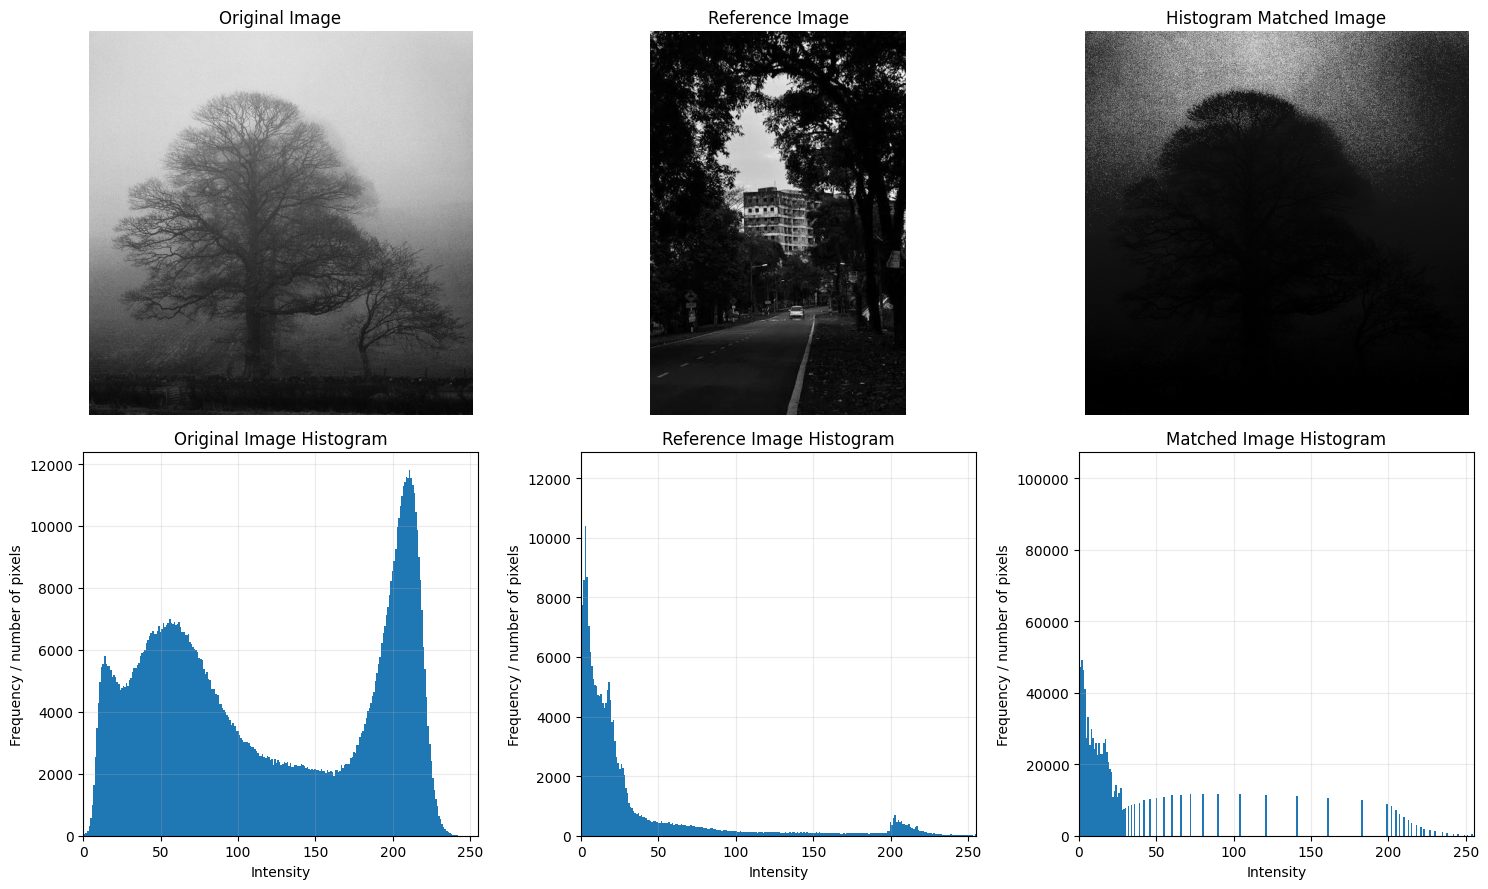

In [32]:
intensity = np.arange(256)

original_hist = original_hist.flatten()
reference_hist = reference_hist.flatten()
matched_hist = matched_hist.flatten()

plt.figure(figsize=(15, 9))

# Original image
plt.subplot(2, 3, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

# Reference image
plt.subplot(2, 3, 2)
plt.imshow(gray_reference, cmap="gray")
plt.title("Reference Image")
plt.axis("off")

# Matched image
plt.subplot(2, 3, 3)
plt.imshow(matched_image, cmap="gray")
plt.title("Histogram Matched Image")
plt.axis("off")

# Original histogram
plt.subplot(2, 3, 4)
plt.bar(intensity, original_hist, width=1)
plt.title("Original Image Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency / number of pixels")
plt.xlim([0, 255])
plt.grid(alpha=0.25)

# Reference histogram
plt.subplot(2, 3, 5)
plt.bar(intensity, reference_hist, width=1)
plt.title("Reference Image Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency / number of pixels")
plt.xlim([0, 255])
plt.grid(alpha=0.25)

# Matched histogram
plt.subplot(2, 3, 6)
plt.bar(intensity, matched_hist, width=1)
plt.title("Matched Image Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency / number of pixels")
plt.xlim([0, 255])
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()